# Parquet Export
Preview a prepared Parquet shard that now packs tensors and PNG images into Arrow-typed columns for quick inspection before sharing on Hugging Face.

In [1]:
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq


def tensor_from_arrow(raw):
    arr = np.asarray(raw, dtype=np.float32)
    if arr.ndim != 3 or arr.shape[2] != 3:
        raise ValueError(f"Expected [H, W, 3] tensor, got {arr.shape}")
    return arr


def image_from_bytes(raw):
    if raw is None:
        return None
    try:
        from PIL import Image
    except ImportError as exc:
        raise ImportError("Install Pillow (`pip install pillow`) to decode image bytes") from exc
    with Image.open(BytesIO(raw)) as img:
        return np.array(img.convert("RGB"))


root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
export_root = root / "outputs" / "export"

row = None
tensor = None
image = None
path_free = None
path_obstacles = None
shard = None

if not export_root.exists():
    print(f"No prepared export found at {export_root}. Run `passage prepare` first.")
else:
    res_dirs = [p for p in export_root.iterdir() if p.is_dir() and p.name.isdigit()]
    if not res_dirs:
        print(f"No resolution directories found in {export_root}.")
    else:
        res_dir = sorted(res_dirs, key=lambda p: int(p.name))[0]
        shard = next((res_dir / "train").glob("data-*.parquet"), None)
        if shard is None:
            print(f"No parquet shards found in {res_dir}/train")
        else:
            table = pq.read_table(shard)
            print(table.schema)
            row = table.slice(0, 1).to_pylist()[0]
            tensor = tensor_from_arrow(row["tensor"])
            path_free = np.asarray(row["path_free"], dtype=int) if row.get("path_free") else None
            path_obstacles = np.asarray(row["path_obstacles"], dtype=int) if row.get("path_obstacles") else None
            image = image_from_bytes(row.get("image"))
            has_image = "yes" if row.get("image") else "no"
            print(f"tensor shape={tensor.shape}, dtype={tensor.dtype}, image bytes={has_image}")

id: string
prefix: string
tensor: fixed_size_list<element: fixed_size_list<element: fixed_size_list<element: float>[3]>[64]>[64]
  child 0, element: fixed_size_list<element: fixed_size_list<element: float>[3]>[64]
      child 0, element: fixed_size_list<element: float>[3]
          child 0, element: float
path_free: list<element: list<element: int32>>
  child 0, element: list<element: int32>
      child 0, element: int32
path_obstacles: list<element: list<element: int32>>
  child 0, element: list<element: int32>
      child 0, element: int32
image: binary
metadata: struct<calibration: struct<max: double, min: double>, crop: struct<bottom_right: struct<lat: double, (... 1544 chars omitted)
  child 0, calibration: struct<max: double, min: double>
      child 0, max: double
      child 1, min: double
  child 1, crop: struct<bottom_right: struct<lat: double, lon: double>, center: struct<lat: double, lon: double>, max (... 112 chars omitted)
      child 0, bottom_right: struct<lat: double, 

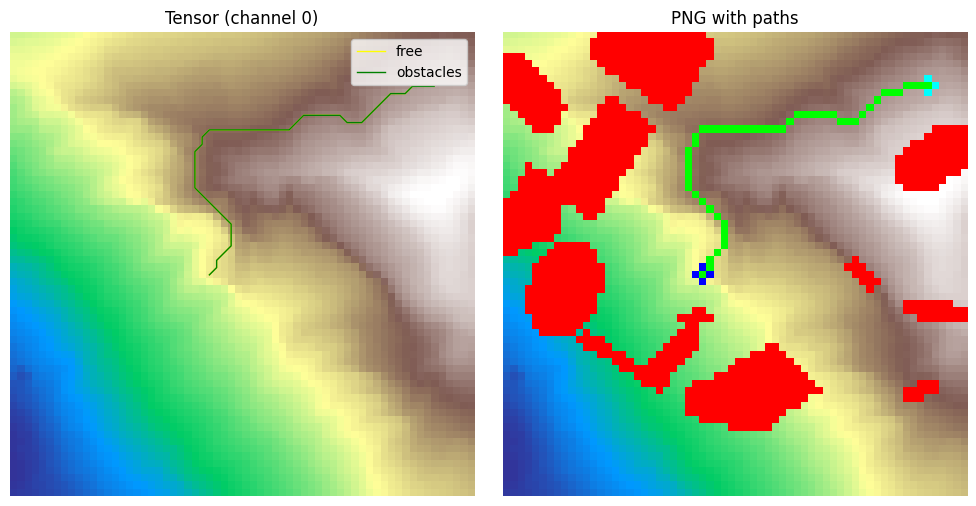

In [2]:
if tensor is not None:
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    axes[0].imshow(tensor[:, :, 0], cmap="terrain")
    if path_free is not None and path_free.size:
        axes[0].plot(path_free[:, 1], path_free[:, 0], color="yellow", linewidth=1, label="free")
    if path_obstacles is not None and path_obstacles.size:
        axes[0].plot(path_obstacles[:, 1], path_obstacles[:, 0], color="green", linewidth=1, label="obstacles")
    axes[0].set_title("Tensor (channel 0)")
    axes[0].axis("off")
    if axes[0].lines:
        axes[0].legend(loc="upper right")

    if image is not None:
        axes[1].imshow(image)
        axes[1].set_title("PNG with paths")
        axes[1].axis("off")
    else:
        axes[1].set_visible(False)

    plt.tight_layout()
    plt.show()
elif shard is not None:
    print("Shard loaded but tensor missing?")
else:
    print("Nothing to show yet.")

In [3]:
# Optional: Hugging Face datasets demo (robust loading without explicit features)
import datasets as ds
import numpy as np

if shard:
    # Load without specifying features to let datasets infer the schema from Arrow
    parquet_ds = ds.load_dataset("parquet", data_files=str(shard), split="train")
    # Cast binary image column to Image feature so it can be displayed/decoded by datasets
    try:
        parquet_ds = parquet_ds.cast_column("image", ds.Image())
    except Exception:
        # If cast fails, continue with raw bytes (Pillow can still decode from bytes in notebook cells)
        pass
    sample = parquet_ds[0]
    tensor = np.asarray(sample["tensor"], dtype=np.float32)
    print("keys:", list(sample.keys()))
    print("tensor.shape:", tensor.shape, "dtype:", tensor.dtype)
    if sample.get("image") is not None:
        print("image available (decoded by datasets.Image or raw bytes)")
    else:
        print("no image in this row")
else:
    print("Set `shard` above before running this cell.")

/home/t0300081/projects/PASSAGE/passage/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


keys: ['id', 'prefix', 'tensor', 'path_free', 'path_obstacles', 'image', 'metadata']
tensor.shape: (64, 64, 3) dtype: float32
image available (decoded by datasets.Image or raw bytes)


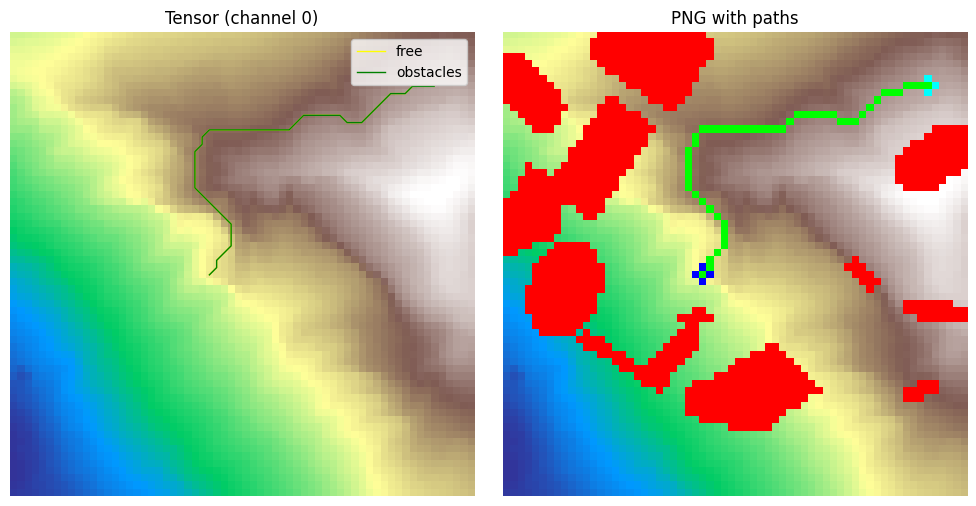

In [4]:
# Plot a sample from the huggingface `parquet_ds` (change idx to view other rows)
idx = 0
sample = parquet_ds[idx]

tensor = np.asarray(sample["tensor"], dtype=np.float32)
path_free = np.asarray(sample.get("path_free"), dtype=int) if sample.get("path_free") else None
path_obstacles = np.asarray(sample.get("path_obstacles"), dtype=int) if sample.get("path_obstacles") else None

# Decode image whichever form datasets provided (PIL.Image, raw bytes, or None)
img_raw = sample.get("image")
if img_raw is None:
    image_ds = None
elif hasattr(img_raw, "convert"):  # PIL Image
    image_ds = np.array(img_raw.convert("RGB"))
elif isinstance(img_raw, (bytes, bytearray)):
    image_ds = image_from_bytes(img_raw)
else:
    try:
        image_ds = np.array(img_raw)
    except Exception:
        image_ds = None

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(tensor[:, :, 0], cmap="terrain")
if path_free is not None and path_free.size:
    axes[0].plot(path_free[:, 1], path_free[:, 0], color="yellow", linewidth=1, label="free")
if path_obstacles is not None and path_obstacles.size:
    axes[0].plot(path_obstacles[:, 1], path_obstacles[:, 0], color="green", linewidth=1, label="obstacles")
axes[0].set_title("Tensor (channel 0)")
axes[0].axis("off")
if axes[0].lines:
    axes[0].legend(loc="upper right")

if image_ds is not None:
    axes[1].imshow(image_ds)
    axes[1].set_title("PNG with paths")
    axes[1].axis("off")
else:
    axes[1].set_visible(False)

plt.tight_layout()
plt.show()